# Which motif sites are bound? The default TF binding score

A motif match in open chromatin is only a *candidate* binding site. `epi.tl.tf_binding`
scores every candidate for occupancy by its factor. Since 2026-10 its default is
`method='occupancy'` (`epi.tl.tf_occupancy`). It is a **thermodynamically weighted
motif-accessibility score**, not a footprint:

$$\text{score}_i = \log \sum_{j:\,|c_j-c_i|\le 150} \underbrace{(1 + n_j + 2\,n_j^{\text{short}})}_{\text{accessibility}}\;\underbrace{e^{\beta s_j}}_{\text{Boltzmann affinity}}$$

* $s_j$ — the PWM log-odds of site $j$ (in nats), $\beta = 0.5$ an effective inverse temperature.
  A site is wrapped in a nucleosome, free, or bound; with the factor scarce, occupancy is
  accessibility × Boltzmann weight (Berg & von Hippel 1987; Granek & Clarke 2005; Wasson & Hartemink 2009).
* $n_j$ — Tn5 insertions within ±50 bp of the site; $n_j^{\text{short}}$ those from
  sub-nucleosomal fragments (≤ 120 bp), which come from nucleosome-free DNA.
* the sum runs over the same motif's sites within ±150 bp: a ChIP peak only resolves
  occupancy to about a fragment's length.

There is no training, no per-site fit and no Tn5 bias model, so it runs in one pass over
the fragments. A footprint (protection) term was tested while the score was designed and
did not improve the ranking of ChIP-bound sites, so it is not part of the score.
PRINT's footprint-based probability (Hu *et al.* 2025) is still there, unchanged and
bit-identical to scPrinter, as `method='print'` / `epi.tl.tf_binding_score` — see
[t_print_footprint](t_print_footprint.ipynb).

**Evidence.** Median per-TF AUROC on ENCODE snATAC (accessible motif matches, bound = site
inside the factor's ENCODE ChIP-seq peak); GM12878, HepG2 and MCF-7 were held out after the
constants were frozen on K562:

| | occupancy (default) | TOBIAS | Tn5 count ±100 bp | PRINT | HINT-ATAC |
|---|---|---|---|---|---|
| K562 (design, 88 TFs) | **0.890** | 0.851 | 0.845 | 0.725 | 0.644 |
| GM12878 (36 TFs) | **0.911** | 0.895 | 0.905 | 0.774 | 0.651 |
| HepG2 (131 TFs) | **0.909** | 0.898 | 0.904 | 0.747 | 0.673 |
| MCF-7 (38 TFs) | **0.887** | 0.843 | 0.847 | 0.725 | 0.644 |

On GM12878 (both) and HepG2 (Tn5) the margin over TOBIAS / the plain count is within
bootstrap noise; over PRINT and HINT it is large everywhere.

This notebook reproduces the comparison on a small, public slice: chromosome 19 of the
same ENCODE K562 snATAC data and six K562 ChIP-seq sets.

## Part 1 · Setup

In [1]:
%matplotlib inline
import os, sys, pathlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata as ad
from sklearn.metrics import roc_auc_score


def _find_repo(start):  # works from the source tree or a pip install
    p = pathlib.Path(start).resolve()
    for cand in (p, *p.parents):
        if (cand / 'epione' / '__init__.py').exists():
            return cand
    return None


CODE = (pathlib.Path(os.environ['EPIONE_SRC']) if os.environ.get('EPIONE_SRC')
        else _find_repo(pathlib.Path.cwd()))
if CODE is not None:
    sys.path.insert(0, str(CODE))

import epione as epi

# Inputs: `python t_tf_binding_data.py OUT_DIR --fasta GRCh38.fa` (next to this notebook)
DATA  = pathlib.Path(os.environ.get('EPIONE_TFB_DATA', 'k562_chr19'))
FRAG, FASTA = DATA / 'fragments.chr19.tsv.gz', DATA / 'chr19.fa'
for p in (FRAG, FASTA, DATA / 'peaks.chr19.bed', DATA / 'motifs.jaspar'):
    if not p.exists():
        raise FileNotFoundError(f'{p} - run t_tf_binding_data.py first')
N_JOBS = int(os.environ.get('SLURM_CPUS_PER_TASK', 8))

C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#8a5cd0']
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.linewidth': 0.8, 'axes.labelcolor': INK2,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlecolor': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'grid.color': GRID, 'grid.linewidth': 0.6, 'legend.frameon': False,
    'legend.fontsize': 9, 'font.size': 10, 'lines.linewidth': 2.0, 'figure.dpi': 110,
})

## Part 2 · Cells, peaks and candidate sites

Two ENCODE K562 snATAC runs pooled into one pseudobulk; MACS3 peaks (1 kb around each
summit). Candidate sites are MOODS matches of six JASPAR 2024 motifs inside the peaks
(`epi.tl.hint_match_motifs`, false-positive rate 5e-5); its `score` column is the log2-odds
the occupancy score uses. Sites closer than 100 bp to a peak edge are dropped, because PRINT
cannot score them and we compare the two on the same sites.

In [2]:
cells = open(DATA / 'cells.txt').read().split()
adata = ad.AnnData(obs=pd.DataFrame({'all': pd.Categorical(['all'] * len(cells))}, index=cells))
adata.uns['files'] = {'fragments': str(FRAG)}
peaks = pd.read_csv(DATA / 'peaks.chr19.bed', sep='\t', header=None, names=['chrom', 'start', 'end'])
print(f'{adata.n_obs:,} cells, {len(peaks):,} peaks on chr19')

hits = epi.tl.hint_match_motifs(peaks, DATA / 'motifs.jaspar', FASTA, fpr=5e-5)
hits['tf'] = hits['name'].str.split('.').str[-1]
# peak of each site, and PRINT's context rule (centre > 100 bp from the region edges)
centre = (hits.start + hits.end) // 2
k = np.searchsorted(peaks.start.values, centre.values, side='right') - 1
rel = centre.values - peaks.start.values[k]
sites = hits[(rel > 100) & (rel <= 900)].drop_duplicates(['tf', 'start', 'end']).reset_index(drop=True)
sites.groupby('tf').size().rename('sites').to_frame().T

48,632 cells, 10,419 peaks on chr19


tf,CTCF,GABPA,MAFK,NRF1,REST,USF1
sites,3459,2384,4240,1714,2330,986


## Part 3 · The default score

One call. `motif_key` names the column that says which factor a site belongs to;
`score_key` (default `'score'`) is the PWM log-odds.

In [3]:
t0 = time.perf_counter()
occ = epi.tl.tf_binding(adata, sites, motif_key='tf', n_jobs=N_JOBS)
t_occ = time.perf_counter() - t0
print(f'{len(sites):,} sites scored in {t_occ:.1f} s on {N_JOBS} workers')
occ.to_frame()[['chrom', 'start', 'end', 'tf', 'score', 'n_insertions', 'n_short', 'occupancy_score']].head()

└─ tf_occupancy: 15,113 sites (15,112 unique), 6 motifs x 1 groups
15,113 sites scored in 7.3 s on 8 workers


,chrom,start,end,tf,score,n_insertions,n_short,occupancy_score
0,chr19,76371,76383,NRF1,10.975076,11.0,11.0,7.330032
1,chr19,82087,82097,GABPA,11.724332,18.0,0.0,7.007783
2,chr19,83978,83988,GABPA,11.472537,44.0,10.0,8.150466
3,chr19,83890,83900,MAFK,17.404536,149.0,42.0,11.487274
4,chr19,89317,89332,CTCF,12.201932,96.0,6.0,8.920215


## Part 4 · Ground truth and the comparison

A site counts as bound if its centre lies in the factor's ENCODE conservative IDR ChIP-seq
peak. Against it we rank the same sites by: the default score; PRINT's binding probability
(`method='print'`, PRINT CNN bias, the published dispersion and binding models); the plain
Tn5 insertion count within ±100 bp (accessibility alone); and the PWM score alone.

In [4]:
def in_chip(tf, centres):
    ch = pd.read_csv(DATA / 'chip' / f'{tf}.bed', sep='\t', header=None, usecols=[1, 2]).sort_values(1)
    s, e = ch[1].values, np.maximum.accumulate(ch[2].values)
    j = np.searchsorted(s, centres, side='right') - 1
    return (j >= 0) & (e[np.maximum(j, 0)] > centres)

sites['centre'] = (sites.start + sites.end) // 2
sites['bound'] = False
for tf, ix in sites.groupby('tf').indices.items():
    sites.loc[ix, 'bound'] = in_chip(tf, sites.centre.values[ix])
sites.groupby('tf').bound.agg(['size', 'sum', 'mean']).rename(columns={'size': 'sites', 'sum': 'bound', 'mean': 'fraction'}).T.round(3)

tf,CTCF,GABPA,MAFK,NRF1,REST,USF1
sites,3459.000,2384.000,4240.000,1714.0,2330.000,986.000
bound,1372.000,441.000,183.000,1200.0,312.000,300.000
fraction,0.397,0.185,0.043,0.7,0.134,0.304


In [5]:
t0 = time.perf_counter()
prt = epi.tl.tf_binding(adata, sites, method='print', regions=peaks, groupby='all',
                        bias=epi.tl.tn5_bias(str(FASTA)), keep_tracks=False, verbose=False)
t_print = time.perf_counter() - t0
key = prt.sites.assign(p=prt.score[0]).drop_duplicates(['center', 'strand']).set_index(['center', 'strand']).p
sites['print'] = key.reindex(pd.MultiIndex.from_arrays([sites.centre, sites.strand])).values
n100, _ = epi.tl.site_insertion_counts(str(FRAG), cells, np.zeros(len(cells), int), 1,
                                       sites.chrom.values, sites.centre.values, window=100, n_jobs=N_JOBS)
sites['tn5_100'] = n100[0]
sites['occupancy'] = occ.score[0]
print(f'PRINT: {t_print:.0f} s   default: {t_occ:.1f} s   ({t_print / t_occ:.0f}x)   unscored by PRINT: {sites["print"].isna().sum()}')

PRINT: 3974 s   default: 7.3 s   (544x)   unscored by PRINT: 0


Two ablations of the default, recomputed from the same counts with
`epi.tl.occupancy_from_counts`: the site on its own (no neighbourhood sum) and no motif
term ($\beta = 0$, accessibility only but with the short-fragment weighting and the sum).

In [6]:
site_only, _ = epi.tl.occupancy_from_counts(sites, occ.n_all, occ.n_short, motif_key='tf', radius=0)
no_pwm, _ = epi.tl.occupancy_from_counts(sites, occ.n_all, occ.n_short, motif_key='tf', beta=0.0)
sites['site only'], sites['no PWM'] = site_only[0], no_pwm[0]

METHODS = {'occupancy': 'occupancy (default)', 'print': 'PRINT', 'tn5_100': 'Tn5 count ±100 bp',
           'score': 'PWM only', 'site only': 'occupancy, site only', 'no PWM': 'occupancy, β = 0'}
auc = pd.DataFrame({lab: {tf: roc_auc_score(g.bound, g[col]) for tf, g in sites.groupby('tf')}
                    for col, lab in METHODS.items()})
auc.loc['median'] = auc.median()
auc.round(3)

,occupancy (default),PRINT,Tn5 count ±100 bp,PWM only,"occupancy, site only","occupancy, β = 0"
CTCF,0.900,0.938,0.821,0.788,0.902,0.863
GABPA,0.898,0.763,0.882,0.608,0.889,0.893
MAFK,0.938,0.868,0.873,0.699,0.923,0.913
NRF1,0.936,0.783,0.913,0.676,0.926,0.930
REST,0.888,0.820,0.797,0.709,0.876,0.838
USF1,0.915,0.852,0.867,0.627,0.900,0.908
median,0.908,0.836,0.870,0.687,0.901,0.900


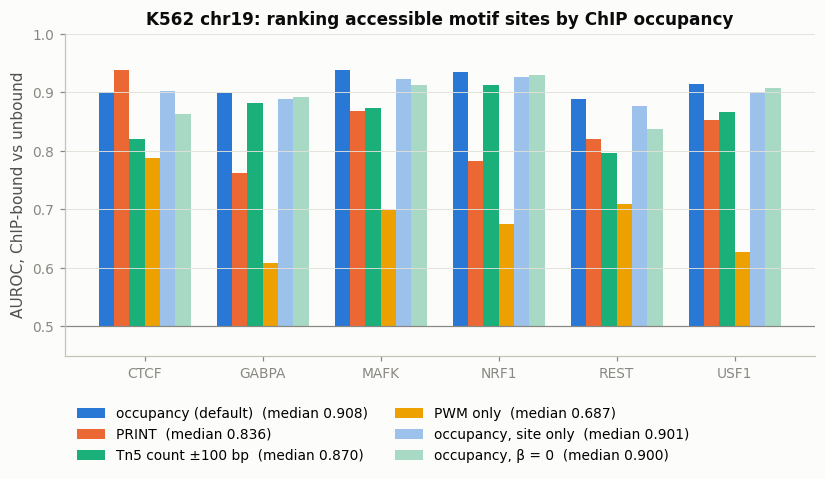

In [7]:
order = list(METHODS.values())
cols = {'occupancy (default)': C[0], 'PRINT': C[1], 'Tn5 count ±100 bp': C[2], 'PWM only': C[3],
        'occupancy, site only': '#9cc2ec', 'occupancy, β = 0': '#a7d9c4'}
tfs = auc.index[:-1]
fig, ax = plt.subplots(figsize=(8.8, 3.8))
w = 0.13
for k, m in enumerate(order):
    x = np.arange(len(tfs)) + (k - (len(order) - 1) / 2) * w
    ax.bar(x, auc.loc[tfs, m] - 0.5, w, bottom=0.5, color=cols[m], label=f'{m}  (median {auc.loc["median", m]:.3f})')
ax.set_xticks(np.arange(len(tfs)), tfs)
ax.set_ylim(0.45, 1.0); ax.axhline(0.5, color=MUTED, lw=0.8)
ax.set_ylabel('AUROC, ChIP-bound vs unbound'); ax.grid(axis='y')
ax.set_title('K562 chr19: ranking accessible motif sites by ChIP occupancy')
ax.legend(ncol=2, loc='upper left', bbox_to_anchor=(0, -0.12))
plt.show()

Read the bars per factor, not only the medians. CTCF is the exception on this slice: its
long, deeply protected footprint is exactly what PRINT models, and PRINT ranks CTCF sites
best. For the other factors footprints carry little beyond accessibility and the motif, and
the default is ahead of PRINT by a wide margin. The two ablations show what each piece buys:
the motif term matters most for CTCF, REST and MAFK and is neutral (within 0.01) for GABPA,
NRF1 and USF1; the neighbourhood sum helps for five of the six. Timings were taken on a shared
node, so read the PRINT/default ratio as an order of magnitude (same-node benchmarks: ~70x). Six factors on one chromosome are an
illustration; the evidence table at the top is the evaluation.

## Part 5 · What the score is doing

Both axes matter. For CTCF, the fraction of ChIP-bound sites rises with accessibility *and*
with motif strength; the default score's contour lines (straight lines of slope $-1/\beta$ in
these coordinates, before the neighbourhood sum) cut across both, which is why it beats
either axis alone.

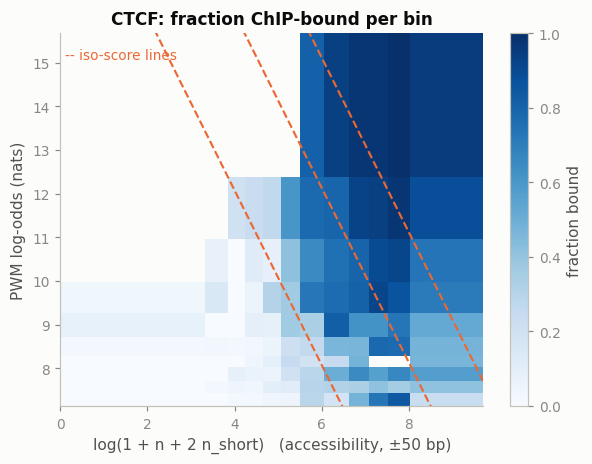

In [8]:
tf = 'CTCF'
g = sites[sites.tf == tf]
xa = np.log1p(occ.n_all[0][g.index] + 2 * occ.n_short[0][g.index])
ys = g.score.values * np.log(2)
xb = np.quantile(xa, np.linspace(0, 1, 13)); yb = np.quantile(ys, np.linspace(0, 1, 11))
H = np.full((len(yb) - 1, len(xb) - 1), np.nan)
ix = np.clip(np.searchsorted(xb, xa, side='right') - 1, 0, len(xb) - 2)
iy = np.clip(np.searchsorted(yb, ys, side='right') - 1, 0, len(yb) - 2)
for a in range(H.shape[1]):
    for b in range(H.shape[0]):
        m = (ix == a) & (iy == b)
        if m.sum() >= 10:
            H[b, a] = g.bound.values[m].mean()
fig, ax = plt.subplots(figsize=(6.2, 4.4))
im = ax.pcolormesh(xb, yb, H, cmap='Blues', vmin=0, vmax=1, shading='flat')
xx = np.linspace(xb[0], xb[-1], 50)
for c in np.quantile(xa + 0.5 * ys, [0.5, 0.75, 0.9]):
    ax.plot(xx, (c - xx) / 0.5, color=C[1], lw=1.4, ls='--')
ax.set_xlim(xb[0], xb[-1]); ax.set_ylim(yb[0], yb[-1])
ax.set_xlabel('log(1 + n + 2 n_short)   (accessibility, ±50 bp)')
ax.set_ylabel('PWM log-odds (nats)')
ax.set_title(f'{tf}: fraction ChIP-bound per bin')
fig.colorbar(im, ax=ax, label='fraction bound'); ax.text(xb[0] + 0.1, yb[-1] - 0.6, '-- iso-score lines', color=C[1], fontsize=9)
plt.show()

## Part 6 · Groups and runtime

`groupby` gives one score per pseudobulk (here the two ENCODE runs), from one pass over the
fragments. Within a group, compare sites of one factor: the score is a log-occupancy up to a
per-factor constant (the chemical potential), so its absolute level is not a probability.

In [9]:
adata.obs['run'] = pd.Categorical([c.split('#')[0] for c in adata.obs_names])
t0 = time.perf_counter()
by_run = epi.tl.tf_binding(adata, sites, motif_key='tf', groupby='run', n_jobs=N_JOBS, verbose=False)
print(f'{len(by_run.groups)} groups in {time.perf_counter() - t0:.1f} s:', by_run.groups)
r = np.corrcoef(by_run.score)[0, 1]
print(f'per-site score correlation between the two runs: r = {r:.3f}')
pd.DataFrame({'method': ['tf_binding (occupancy, default)', "tf_binding(method='print')"],
              'wall time (s)': [round(t_occ, 1), round(t_print, 1)],
              'sites': [len(sites), len(sites)]})

2 groups in 13.9 s: ['ENCSR308ZGJ', 'ENCSR332SXG']
per-site score correlation between the two runs: r = 0.986


,method,wall time (s),sites
0,"tf_binding (occupancy, default)",7.3,15113
1,tf_binding(method='print'),3974.0,15113


## Summary

| | |
|---|---|
| Call | `epi.tl.tf_binding(adata, motif_sites, motif_key=..., groupby=...)` |
| Score | log Σ over the factor's sites within ±150 bp of accessibility × exp(β · PWM) |
| Needs | fragments file + motif matches with PWM scores; no bias model, no training |
| Not | a footprint: protection terms did not help on ChIP ground truth |
| PRINT | `method='print'` / `epi.tl.tf_binding_score`, unchanged ([t_print_footprint](t_print_footprint.ipynb)) |
| Aggregate footprints | `epi.tl.get_footprints`, `epi.tl.multi_scale_footprint_region` ([t_footprint](t_footprint.ipynb)) |